In [2]:
import logging
import json
import sys
import types
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path

from IPython.display import display

# --- Compatibilidade RAGAS / langchain-community ---------------------------
# A ragas (todas as versões publicadas) importa incondicionalmente
# `langchain_community.chat_models.vertexai.ChatVertexAI`, um submódulo que
# já não existe na langchain-community actual (está a ser descontinuada — a
# integração VertexAI mudou para o pacote `langchain-google-vertexai`, que é
# um caminho de import DIFERENTE e não repõe o submódulo antigo — por isso
# instalar esse pacote não resolve o ModuleNotFoundError). Como este projecto
# nunca usa o VertexAI (só Ollama local), registamos aqui um stub inofensivo
# em sys.modules ANTES de importar a ragas.
_vertexai_stub = types.ModuleType("langchain_community.chat_models.vertexai")


class _UnavailableVertexAI:
    def __init__(self, *args, **kwargs):
        raise ImportError("VertexAI não está disponível — usa-se Ollama local.")


_vertexai_stub.ChatVertexAI = _UnavailableVertexAI
sys.modules["langchain_community.chat_models.vertexai"] = _vertexai_stub

# A ragas também aplica nest_asyncio.apply() ao ser importada (para poder
# correr dentro de notebooks/event loops já activos). Isso quebra a detecção
# de biblioteca assíncrona do sniffio/httpcore usada pelo cliente HTTP do
# Ollama — as chamadas reais à API do Ollama acabam por falhar com
# "Timeout should be used inside a task" ao fechar a ligação. Desactivamos
# o patch antes de o ragas.executor o aplicar — a avaliação é corrida numa
# thread à parte (ver a função evaluate() mais abaixo), onde não há event
# loop já activo, por isso o nest_asyncio não faz falta nenhuma.
import nest_asyncio

nest_asyncio.apply = lambda *args, **kwargs: None

from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_ollama import ChatOllama
from ragas import evaluate as ragas_evaluate
from ragas.dataset_schema import EvaluationDataset, SingleTurnSample
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.evaluation import EvaluationResult
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import (
    FactualCorrectness,
    Faithfulness,
    LLMContextPrecisionWithReference,
    LLMContextRecall,
    ResponseRelevancy,
)
from ragas.run_config import RunConfig

logger = logging.getLogger(__name__)

C:\Users\user\AppData\Local\Temp\ipykernel_27484\2520501822.py:43: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import HuggingFaceEmbeddings


In [3]:
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

sys.path.insert(0, str(Path.cwd().parent / "src"))

from rag import RAGPipeline

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

In [5]:
def load_test_dataset(path: Path) -> list[dict[str, str]]:
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    return [dict(question=item["question"], ground_truth=item["ground_truth"]) for item in data]

In [7]:
def _run_pipeline(pipeline: RAGPipeline, examples: list[dict[str, str]]) -> EvaluationDataset:
    samples = []
    for i, example in enumerate(examples, start=1):
        logger.info(f"Processing question {i}/{len(examples)}: {example['question']}")

        response = pipeline.query(example["question"], session_id=None)
        samples.append(
            SingleTurnSample(
                user_input=example["question"],
                response=response.answer,
                retrieved_contexts=[doc.content for doc in response.retrieved_documents],
                reference=example["ground_truth"],
            )
        )
    return EvaluationDataset(samples=samples)

In [8]:
def evaluate(examples: list[dict[str, str]], pipeline: RAGPipeline) -> EvaluationResult:
    evaluation_dataset = _run_pipeline(pipeline, examples)

    model_config = pipeline.config.model
    llm = LangchainLLMWrapper(
        ChatOllama(
            model=model_config.model_name,
            base_url=model_config.ollama_base_url,
            temperature=0.0,
        )
    )
    judge_embeddings = LangchainEmbeddingsWrapper(
        HuggingFaceEmbeddings(
            model_name=pipeline.config.retriever.embedding_model,
            model_kwargs={"device": pipeline.config.retriever.embedding_device},
        )
    )

    metrics = [
        Faithfulness(llm=llm),
        ResponseRelevancy(llm=llm, embeddings=judge_embeddings),
        LLMContextPrecisionWithReference(llm=llm),
        LLMContextRecall(llm=llm),
        FactualCorrectness(llm=llm),
    ]

    run_config = RunConfig(timeout=1200, max_workers=1)

    with ThreadPoolExecutor(max_workers=1) as thread_executor:
        future = thread_executor.submit(
            ragas_evaluate, evaluation_dataset, metrics, run_config=run_config
        )
        evaluation_result = future.result()

    return evaluation_result

In [9]:
_BASE_DIR = Path.cwd().parent
_DEFAULT_DATASET = _BASE_DIR / "data" / "evaluation" / "golden_qa.json"
_DEFAULT_OUTPUT = _BASE_DIR / "data" / "evaluation" / "results.csv"

dataset_path = _DEFAULT_DATASET
output_path = _DEFAULT_OUTPUT

print(f"Loading golden dataset from: {dataset_path}")
examples = load_test_dataset(dataset_path)
print(f"Loaded {len(examples)} examples from the golden dataset.")

Loading golden dataset from: c:\Users\user\OneDrive\Desktop\AMIGO DO AGRICULTOR\rag-project\data\evaluation\golden_qa.json
Loaded 8 examples from the golden dataset.


In [10]:
print("Initializing RAG pipeline...")
pipeline = RAGPipeline()

print("Running evaluation...")
result = evaluate(examples, pipeline)

Initializing RAG pipeline...


2026-10-15 20:00:26,618 | INFO | Loading SentenceTransformer model from sentence-transformers/paraphrase-multilingual-mpnet-base-v2.
2026-10-15 20:00:38,279 | INFO | Processing question 1/8: Quero fazer o viveiro da couve, mas o terreno aqui fica encharcado quando chove muito. Como devo fazer os canteiros?


Running evaluation...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-15 20:04:37,220 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:04:37,224 | INFO | Processing question 2/8: As sementes de couve e alface que compramos aos vendedores que passam por aqui muitas vezes não prestam. Como posso produzir e guardar as minhas próprias sementes?


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-15 20:21:46,655 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
C:\Users\user\AppData\Local\Temp\ipykernel_27484\851304678.py:13: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  HuggingFaceEmbeddings(
2026-10-15 20:21:49,457 | INFO | Loading SentenceTransformer model from sentence-transformers/paraphrase-multilingual-mpnet-base-v2.


Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

2026-10-15 20:22:48,477 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:26:55,488 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:31:35,015 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:31:43,929 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:31:52,376 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:33:48,132 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:34:40,014 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:35:37,119 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:36:29,633 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-15 20:37:23,178 | INFO | HTTP Request: POST http://localhost:11434/api/cha

In [17]:
df = result.to_pandas()
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False, encoding="utf-8")

# As colunas de métrica são todas as que não são texto de entrada/saída —
# assim a tabela não depende de sabermos os nomes exactos de antemão.
text_columns = ["user_input", "retrieved_contexts", "response", "reference"]
metric_columns = [c for c in df.columns if c not in text_columns]

print("=== Resultado por pergunta ===")
display_df = df[["user_input", *metric_columns]].copy()
display_df["user_input"] = display_df["user_input"].str.slice(0, 60) + "…"
display_df[metric_columns] = display_df[metric_columns].round(3)
display(display_df)

=== Resultado por pergunta ===


,user_input,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall,factual_correctness(mode=f1)
0,"Quero fazer o viveiro da couve, mas o terreno ...",0.375,0.724,0.000,0.200,0.50
1,As sementes de couve e alface que compramos ao...,1.000,0.688,0.887,0.857,0.00
2,A minha couve tem umas lagartas verdes pequena...,0.375,0.633,0.700,0.833,0.88
3,"Uso medicamentos contra as pragas da couve, ma...",0.250,0.247,1.000,0.263,0.36
4,"Transplantei a alface há uma semana, mas muita...",NaN,0.412,0.950,0.700,0.31
5,Quero melhorar a terra da minha machamba com c...,0.273,0.664,0.000,1.000,0.55
6,Costumo pôr capim à volta das plantas para gua...,0.000,0.462,0.200,0.750,0.08
7,As folhas da minha couve estão com manchas ama...,0.500,0.000,0.500,0.625,0.19


In [12]:
summary_df = df[metric_columns].mean().round(3).to_frame(name="média")

summary_path = output_path.with_name(output_path.stem + "_summary.csv")
summary_df.to_csv(summary_path, encoding="utf-8")

print("\n=== Média por métrica ===")
display(summary_df)


=== Média por métrica ===


,média
faithfulness,0.396
answer_relevancy,0.479
llm_context_precision_with_reference,0.530
context_recall,0.654
factual_correctness(mode=f1),0.359


In [13]:
print(f"Resultados por pergunta guardados em: {output_path}")
print(f"Médias por métrica guardadas em: {summary_path}")

Resultados por pergunta guardados em: c:\Users\user\OneDrive\Desktop\AMIGO DO AGRICULTOR\rag-project\data\evaluation\results.csv
Médias por métrica guardadas em: c:\Users\user\OneDrive\Desktop\AMIGO DO AGRICULTOR\rag-project\data\evaluation\results_summary.csv


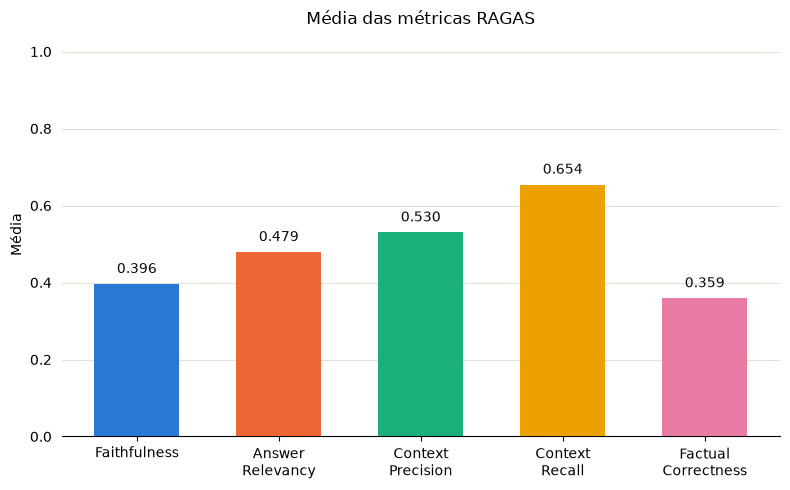

In [15]:
import matplotlib.pyplot as plt

_METRIC_LABELS = {
    "faithfulness": "Faithfulness",
    "answer_relevancy": "Answer\nRelevancy",
    "llm_context_precision_with_reference": "Context\nPrecision",
    "context_recall": "Context\nRecall",
    "factual_correctness(mode=f1)": "Factual\nCorrectness",
}
_BAR_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

labels = [_METRIC_LABELS.get(c, c) for c in summary_df.index]
values = summary_df["média"].to_numpy()
colors = _BAR_COLORS[: len(values)]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, values, color=colors, width=0.6, zorder=3)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#0b0b0b",
    )

ax.set_ylim(0, 1.05)
ax.set_ylabel("Média")
ax.set_title("Média das métricas RAGAS")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)

plt.tight_layout()
plt.show()

In [16]:
std_df = df[metric_columns].std().round(3).to_frame(name="desvio_padrão")

print("\n=== Desvio padrão por métrica ===")
display(std_df)


=== Desvio padrão por métrica ===


,desvio_padrão
faithfulness,0.308
answer_relevancy,0.253
llm_context_precision_with_reference,0.418
context_recall,0.284
factual_correctness(mode=f1),0.284
